# ALS (als_NYGC) — sRGES pipeline (drug summarisation after CS) vs TSR/LMM pipeline

Two ways of turning LINCS L1000 drug signatures into one score per drug, on the same als_NYGC disease
signature (GSE153960, NYGC ALS Consortium, post-mortem CNS tissue):

| | **TSR/LMM pipeline** | **sRGES pipeline** (Chen 2017 / OCTAD) |
|---|---|---|
| drug signatures | level-3 L1000, collapsed per drug **before** CS by a linear mixed model (cell line `all`) | level-5 landmark signatures, **one per instance** (drug × cell line × dose × time), 71 cell lines |
| CS | one per drug (pooled `6h_24h` used here) | one per instance |
| run names | `<config>_TSR` (e.g. `DEG_TSR`) | `<config>` + score |
| per-drug score | the CS itself | collapse **after** CS: `sRGES_weighted` (cell lines weighted by their expression similarity to the ALS CNS samples: CCLE profiles, HPA and GEO GSE144279 profiles for 6 lines without CCLE expression), `sRGES_unweighted`, `best` (most negative instance) |
| drug universe | 3,221 compounds | 12,440 compounds (BRD ids with the same L1000 name pooled; section 2.1) |

Sign convention for every score: **more negative = stronger reversal = better candidate**.

Inputs (tables of `src/case_study_pipeline.py`, steps `weights`, `srges` and `validation` of
`src/case_study/`): `als_NYGC_cell_line_weights.tsv` (weights), `als_NYGC_srges_per_drug.tsv` (per-drug sRGES),
`als_NYGC_known_drug_ranks.tsv` (known drugs in every ranking). TSR runs via `loader.load_cs_run(drug_run_id='all')`.
Known drugs: riluzole and edaravone (approved, disease-modifying), dextromethorphan and quinidine (approved, symptomatic), phenylbutyrate (component of AMX0035). With 5 known drugs the comparison is descriptive: it shows where they fall, it does
not measure the performance of a ranking.

Configurations: `DEG`, `mith`, `mith_LM`, `mith_pw`; each section shows every configuration with CS runs
on all 71 cell lines. In this route `DEG_LM` = `DEG` (the drug signatures are landmark-only).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'axes.grid': True, 'grid.color': '0.75', 'grid.linestyle': '--', 'grid.linewidth': .6})
BLUE, RED = '#1f4e9c', '#c0392b'

DISEASE = 'als_NYGC'
def _find_root(start):
    p = start
    for _ in range(8):
        if os.path.isdir(os.path.join(p, 'connectivity_score', 'input')):
            return p
        p = os.path.dirname(p)
    return None
NETCOS_ROOT = _find_root(os.getcwd())
sys.path.insert(0, os.path.join(NETCOS_ROOT, 'src'))
from loader import load_cs_run

OUT = os.path.join(NETCOS_ROOT, 'other_outputs', 'case_studies', DISEASE)
IMG_DIR = os.path.join(NETCOS_ROOT, 'imgs', 'case_studies', DISEASE)
os.makedirs(IMG_DIR, exist_ok=True)
N_LINES = 71

srges = pd.read_csv(os.path.join(OUT, f'{DISEASE}_srges_per_drug.tsv'), sep='\t')
runs_used = pd.read_csv(os.path.join(OUT, f'{DISEASE}_srges_cs_runs_used.tsv'), sep='\t')
weights = pd.read_csv(os.path.join(OUT, f'{DISEASE}_cell_line_weights.tsv'), sep='\t')
kn = pd.read_csv(os.path.join(OUT, f'{DISEASE}_known_drug_ranks.tsv'), sep='\t')
KNOWN = list(kn.drug_key.unique())

complete = runs_used.groupby('config')['cell_line'].nunique()
CONFIGS = [c for c in ['DEG', 'mith', 'mith_LM', 'mith_pw'] if complete.get(c, 0) == N_LINES]
PENDING = [c for c in ['DEG', 'mith', 'mith_LM', 'mith_pw'] if c not in CONFIGS]
COLLAPSES = ['sRGES_weighted', 'sRGES_unweighted', 'best']
print('cell lines with a CS run per configuration:', complete.to_dict())
print('shown:', CONFIGS, '| without CS runs on all lines:', PENDING)

cell lines with a CS run per configuration: {'DEG': 71, 'mith': 71, 'mith_LM': 71, 'mith_pw': 71}
shown: ['DEG', 'mith', 'mith_LM', 'mith_pw'] | without CS runs on all lines: []


## 1. TSR/LMM drug-collapsed runs (reference, `<config>_TSR`)

The most recent `bin_chen` run of each configuration on drug input `all`, pooled `6h_24h` rows,
drug key = L1000 name (lower case, alphanumerics only).

In [2]:
TSR_CONFIGS = {'DEG': (0, 0, 0), 'DEG_LM': (0, 1, 0), 'mith': (1, 0, 0), 'mith_LM': (1, 1, 0), 'mith_pw': (1, 0, 1)}
key = lambda s: s.astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
tsr = {}
for lab, (m, lm, pw) in TSR_CONFIGS.items():
    df, path, run_id = load_cs_run(disease=DISEASE, landmark_disease=False, drug_run_id='all', mith=m, cs_on_LM=lm,
                                   CS_ON_PATHWAYS=pw, CS_METHOD='bin_chen', verbose=False)
    p = df[df['pert_id'].astype(str).str.endswith('_6h_24h')].copy()
    p['k'] = key(p['pert_id'].str[:-len('_6h_24h')])
    tsr[lab] = p.groupby('k')['connectivity_score'].mean()
    print(f'{lab + "_TSR":12s} {run_id}  drugs {len(tsr[lab])}')

DEG_TSR      30_06_2026_11_55_DEG_bin_chen_connectivity_score  drugs 3221


DEG_LM_TSR   30_06_2026_12_02_DEG_LM_bin_chen_connectivity_score  drugs 3221
mith_TSR     30_06_2026_12_03_mith_bin_chen_connectivity_score  drugs 3221


mith_LM_TSR  30_06_2026_12_09_mith_LM_bin_chen_connectivity_score  drugs 3221


mith_pw_TSR  30_06_2026_12_08_mith_pw_bin_chen_connectivity_score  drugs 3221


## 2. Coverage of the sRGES pipeline

In [3]:
s = srges[srges['config'].isin(CONFIGS)].copy()
s['k'] = key(s['pert_iname'])
cov = s.groupby(['config', 'collapse']).agg(n_drugs=('pert_iname', 'size'), compounds_several_BRD=('n_pert_ids', lambda x: int((x > 1).sum())),
        median_instances=('n_instances', 'median'), drugs_1_instance=('n_instances', lambda x: int((x == 1).sum())),
        median_cell_lines=('n_cell_lines', 'median'), drugs_1_cell_line=('n_cell_lines', lambda x: int((x == 1).sum())))
display(cov)
for c in CONFIGS:
    names = set(s.loc[(s.config == c) & (s.collapse == 'sRGES_unweighted'), 'k'])
    t = set(tsr[c].index)
    print(f'{c}: sRGES compounds {len(names)}, {c}_TSR {len(t)}, shared {len(names & t)}, {c}_TSR-only {len(t - names)}')
lost = 1 - s.loc[s.collapse == 'sRGES_weighted'].groupby('config').size() / s.loc[s.collapse == 'sRGES_unweighted'].groupby('config').size()
print('share of compounds lost by the weighted sRGES (only on lines without a weight):', lost.round(3).to_dict())

n_drugs  compounds_several_BRD  median_instances  drugs_1_instance  median_cell_lines  drugs_1_cell_line
config  collapse                                                                                                                             
DEG     best                           12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted               12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted_top_median     1643                    199               1.0              1171                1.0               1239
        sRGES_unweighted_top_q3          676                     94               1.0               548                1.0                676
        sRGES_weighted                 12421                    426               2.0              5108                2.0               6208
        sRGES_weighted_top_median       1643                    199               1.0              1171                1.0               1239
        sRGES_weighted_top_q3            676                     94               1.0               548                1.0                676
mith    best                           12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted               12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted_top_median     1643                    199               1.0              1171                1.0               1239
        sRGES_unweighted_top_q3          676                     94               1.0               548                1.0                676
        sRGES_weighted                 12421                    426               2.0              5108                2.0               6208
        sRGES_weighted_top_median       1643                    199               1.0              1171                1.0               1239
        sRGES_weighted_top_q3            676                     94               1.0               548                1.0                676
mith_LM best                           12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted               12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted_top_median     1643                    199               1.0              1171                1.0               1239
        sRGES_unweighted_top_q3          676                     94               1.0               548                1.0                676
        sRGES_weighted                 12421                    426               2.0              5108                2.0               6208
        sRGES_weighted_top_median       1643                    199               1.0              1171                1.0               1239
        sRGES_weighted_top_q3            676                     94               1.0               548                1.0                676
mith_pw best                           12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted               12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted_top_median     1643                    199               1.0              1171                1.0               1239
        sRGES_unweighted_top_q3          676                     94               1.0               548                1.0                676
        sRGES_weighted                 12421                    426               2.0              5108                2.0               6208
        sRGES_weighted_top_median       1643                 

DEG: sRGES compounds 12440, DEG_TSR 3221, shared 3076, DEG_TSR-only 145
mith: sRGES compounds 12440, mith_TSR 3221, shared 3076, mith_TSR-only 145
mith_LM: sRGES compounds 12440, mith_LM_TSR 3221, shared 3076, mith_LM_TSR-only 145
mith_pw: sRGES compounds 12440, mith_pw_TSR 3221, shared 3076, mith_pw_TSR-only 145
share of compounds lost by the weighted sRGES (only on lines without a weight): {'DEG': 0.002, 'mith': 0.002, 'mith_LM': 0.002, 'mith_pw': 0.002}


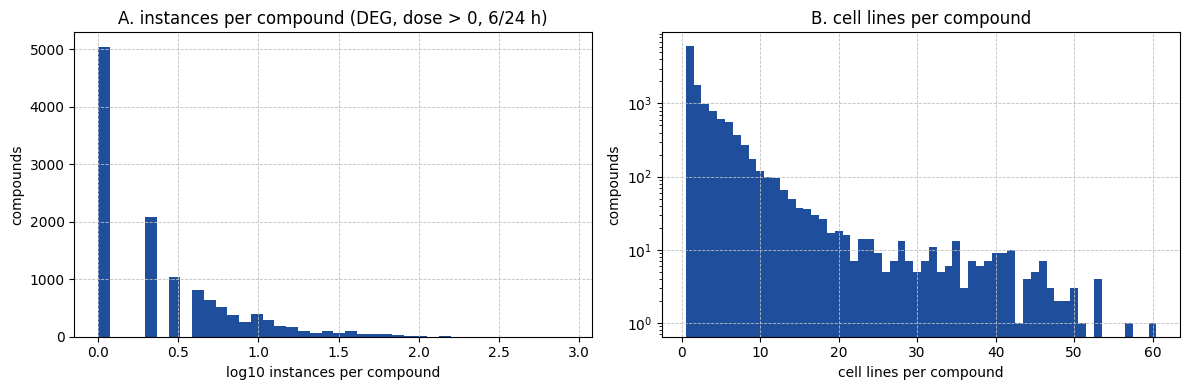

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
u = s[(s.collapse == 'sRGES_unweighted') & (s.config == CONFIGS[0])]
ax[0].hist(np.log10(u['n_instances']), bins=40, color=BLUE)
ax[0].set_xlabel('log10 instances per compound'); ax[0].set_ylabel('compounds')
ax[0].set_title(f'A. instances per compound ({CONFIGS[0]}, dose > 0, 6/24 h)')
ax[1].hist(u['n_cell_lines'], bins=np.arange(0.5, u['n_cell_lines'].max() + 1.5), color=BLUE)
ax[1].set_xlabel('cell lines per compound'); ax[1].set_ylabel('compounds'); ax[1].set_yscale('log')
ax[1].set_title('B. cell lines per compound')
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_coverage.png'), dpi=120); plt.show()

### 2.1 Drug universes: own universe vs shared (TSR ∩ per-instance)

Both routes give **one score per compound**: the TSR route after the per-drug LMM, the
per-instance route after collapsing the instance CS (`sRGES`, `wsRGES`, `best`).
Percentiles are computed over compounds, keyed on `drug_key` (normalised L1000 name;
all BRD ids of a name pooled). Cell lines only decide which instances enter a compound's score.

**Own universe** = the compounds a ranking scores:
- TSR rankings (all 5 configurations): 3,221 compounds (GSE92742 level 3, all instances).
- `sRGES` / `best`: 12,440 compounds (Chen 2017 level-5 gold set, 66,511 instances,
  dose > 0 at 6 or 24 h, all 71 lines).
- `wsRGES`: 12,419 compounds (only the 64 lines with a weight: 58 from CCLE, 4 from HPA, NPC and NEU
  from GEO GSE144279; compounds profiled only on the 7 unweighted lines ASC, CD34, FIBRNPC, HS27A,
  NKDBA, PHH, SKB drop out).
- Top-line rankings (`_topQ3`, `_topMed`, section 10): only the compounds profiled on at least
  one top line.

**Shared set** (`percentile_shared_DEG` in the tables; "TSR ∩ per-instance" in the plots) =
the 3,076 compounds in both universes (3,071 for `wsRGES`). It depends only on which
compounds the two LINCS pools contain, not on the disease signature, so it is the same
for every configuration (`DEG`, `mith`, `mith_LM`, `mith_pw`); the "DEG" in the column name
only marks where it was first defined.

**Why the universes differ:**
- *TSR-only (145):* no instance passes the gold-set filter. Most are compounds absent from
  the gold set (BRD codes, tool compounds, some drugs, e.g. chlorthalidone, guanfacine,
  ixazomib, sonidegib); the others are esters, salts or prodrugs whose parent compound is in the
  gold set under its own name (e.g. dexamethasone acetate, hydrocortisone acetate / valerate /
  hemisuccinate, prednisolone acetate, retinyl acetate).
- *Per-instance-only (9,364):* compounds the TSR/LMM step did not keep, among them compounds
  profiled only at 6 h (count in the cell below).

In [5]:
def pct(s):
    """Percentile within a ranking: rank(pct) x 100, ascending score (low = stronger reversal)."""
    return s.rank(pct=True) * 100


def consensus(W, cols):
    """Percentiles recomputed on the compounds scored by every ranking in cols, then averaged."""
    P = W[cols].dropna().apply(pct)
    P['mean_pct'] = P.mean(axis=1)
    P['consensus_rank'] = P['mean_pct'].rank(method='min').astype(int)
    return P.sort_values('mean_pct')


# one score per compound for every ranking: TSR (section 1, pooled 6h_24h) and per-instance collapses
REN = {'sRGES_unweighted': 'sRGES', 'sRGES_weighted': 'wsRGES', 'best': 'best',
       'sRGES_unweighted_top_q3': 'sRGES_topQ3', 'sRGES_weighted_top_q3': 'wsRGES_topQ3',
       'sRGES_unweighted_top_median': 'sRGES_topMed', 'sRGES_weighted_top_median': 'wsRGES_topMed'}
_sp = srges.assign(k=srges['pert_iname'].astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True))
_sp['ranking'] = _sp['config'] + '_' + _sp['collapse'].map(REN)
W = pd.concat([_sp.groupby(['k', 'ranking'])['score'].mean().unstack()] +
              [v.rename(f'{cfg}_TSR') for cfg, v in tsr.items()], axis=1)
NAME = _sp.drop_duplicates('k').set_index('k')['pert_iname'].reindex(W.index)
NAME = NAME.fillna(pd.Series(W.index, index=W.index))


u_tsr, u_pi = set(W['DEG_TSR'].dropna().index), set(W['DEG_sRGES'].dropna().index)
print(f"DEG_TSR {len(u_tsr)}; DEG_sRGES {len(u_pi)}; DEG_wsRGES {W['DEG_wsRGES'].notna().sum()}")
print(f"shared {len(u_tsr & u_pi)} (wsRGES: {len(u_tsr & set(W['DEG_wsRGES'].dropna().index))}); "
      f"TSR only {len(u_tsr - u_pi)}; per-instance only {len(u_pi - u_tsr)}")

DEG_TSR 3221; DEG_sRGES 12440; DEG_wsRGES 12419
shared 3076 (wsRGES: 3071); TSR only 145; per-instance only 9364


## 3. Score distributions

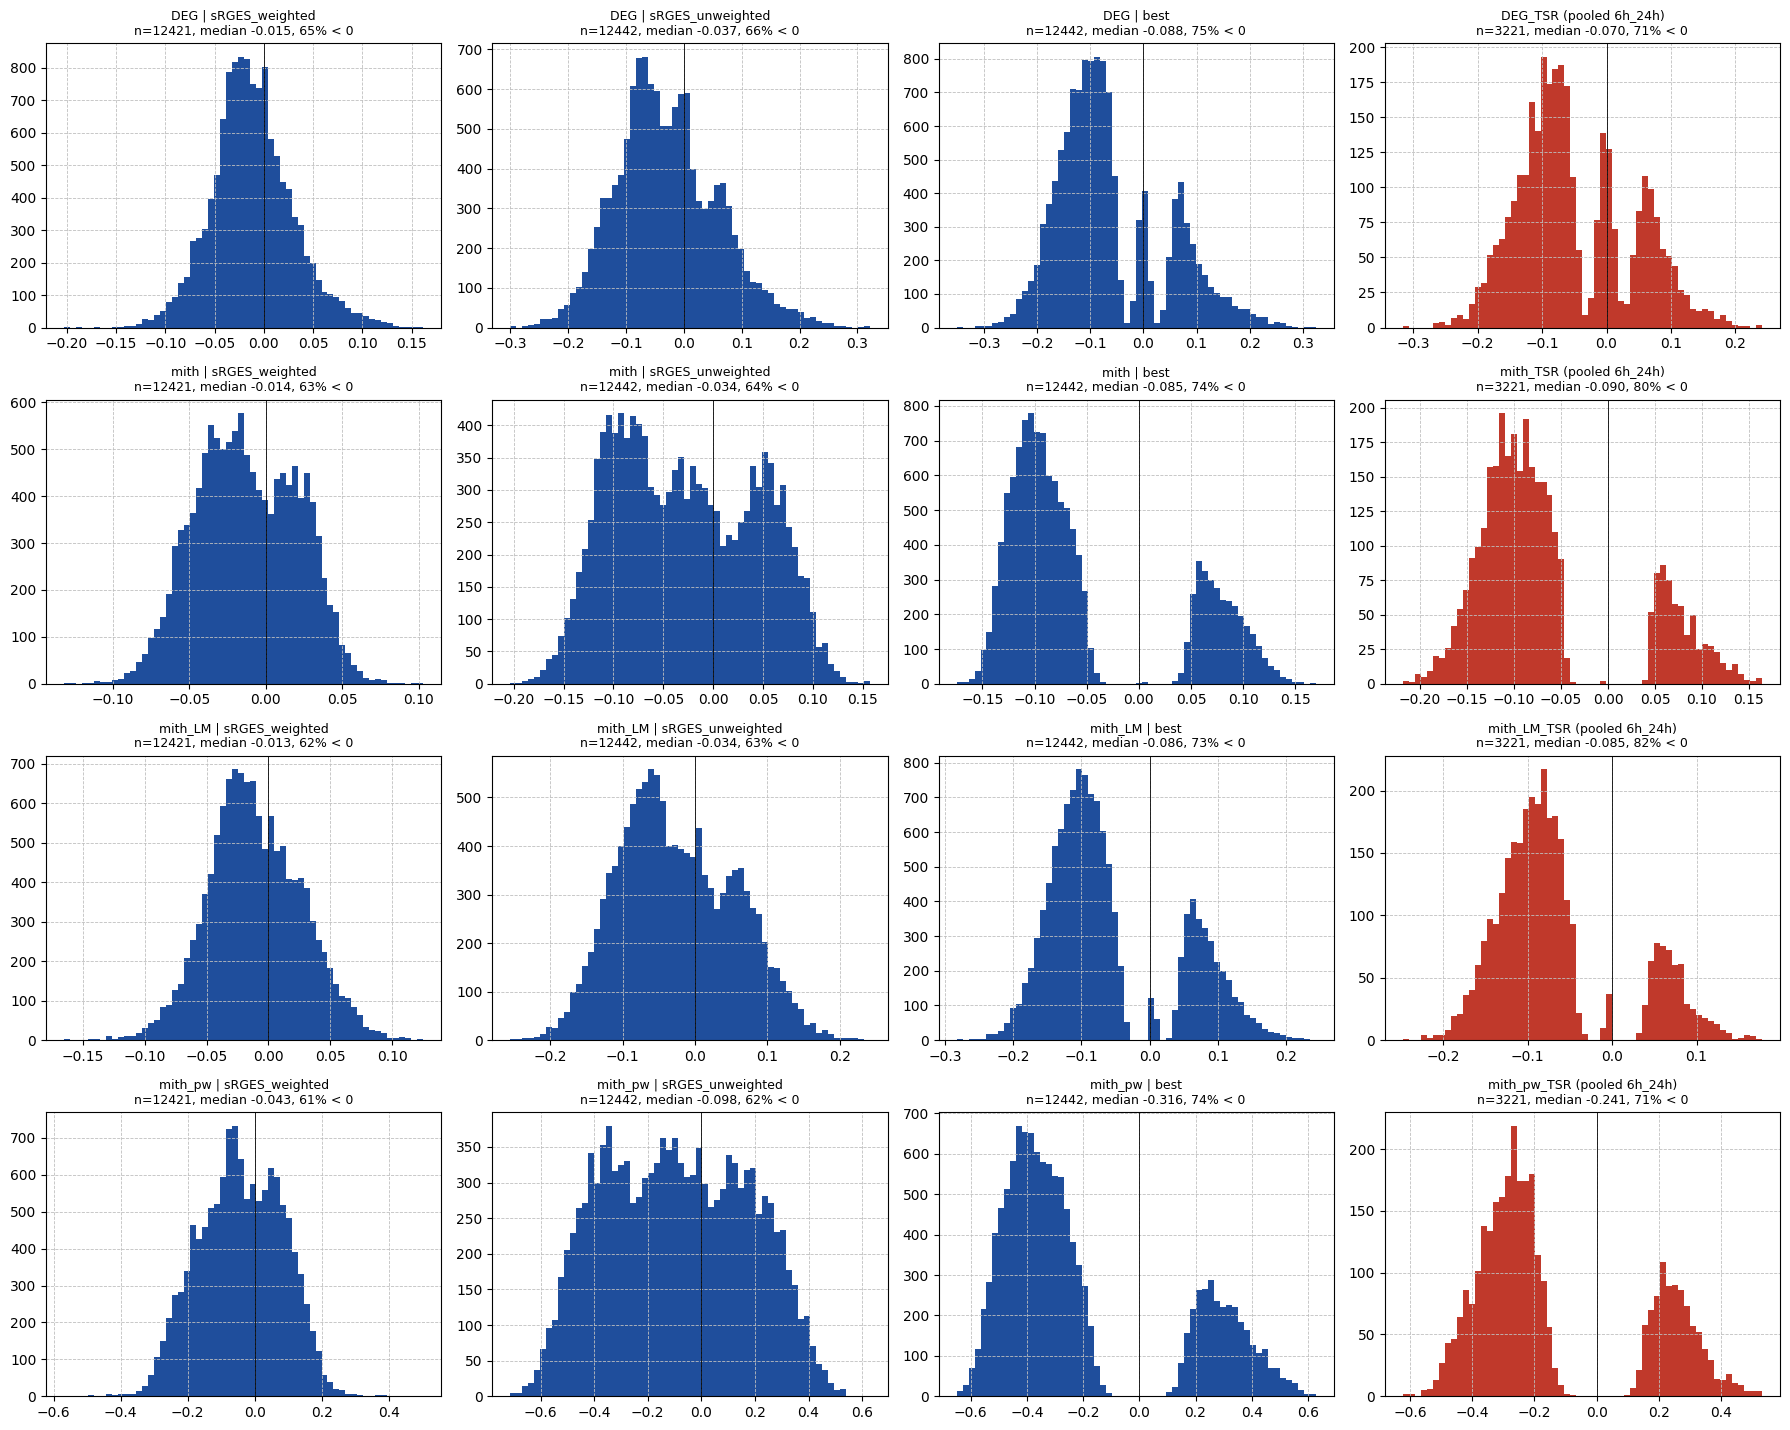

In [6]:
fig, axes = plt.subplots(len(CONFIGS), 4, figsize=(18, 3.6 * len(CONFIGS)), squeeze=False)
for i, c in enumerate(CONFIGS):
    for j, coll in enumerate(COLLAPSES):
        v = s[(s.config == c) & (s.collapse == coll)]['score']
        a = axes[i, j]; a.hist(v, bins=60, color=BLUE)
        a.axvline(0, color='k', lw=.6)
        a.set_title(f'{c} | {coll}\nn={len(v)}, median {v.median():+.3f}, {100 * (v < 0).mean():.0f}% < 0', fontsize=9)
    v = tsr[c]; a = axes[i, 3]; a.hist(v, bins=60, color=RED); a.axvline(0, color='k', lw=.6)
    a.set_title(f'{c}_TSR (pooled 6h_24h)\nn={len(v)}, median {v.median():+.3f}, {100 * (v < 0).mean():.0f}% < 0', fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_score_distributions.png'), dpi=120); plt.show()

## 4. Agreement between collapses and with the TSR pipeline

Spearman correlation of per-compound scores, on the compounds present in both (sRGES compounds
matched to TSR by L1000 name; several compounds with the same name are averaged).

,config,x,y,n,spearman
0,DEG,sRGES_weighted,sRGES_unweighted,12419,0.969
1,DEG,sRGES_weighted,best,12419,0.663
2,DEG,sRGES_weighted,DEG_TSR,3071,0.496
3,DEG,sRGES_unweighted,best,12440,0.690
4,DEG,sRGES_unweighted,DEG_TSR,3076,0.520
5,DEG,best,DEG_TSR,3076,0.395
6,mith,sRGES_weighted,sRGES_unweighted,12419,0.965
7,mith,sRGES_weighted,best,12419,0.630
8,mith,sRGES_weighted,mith_TSR,3071,0.376
9,mith,sRGES_unweighted,best,12440,0.654


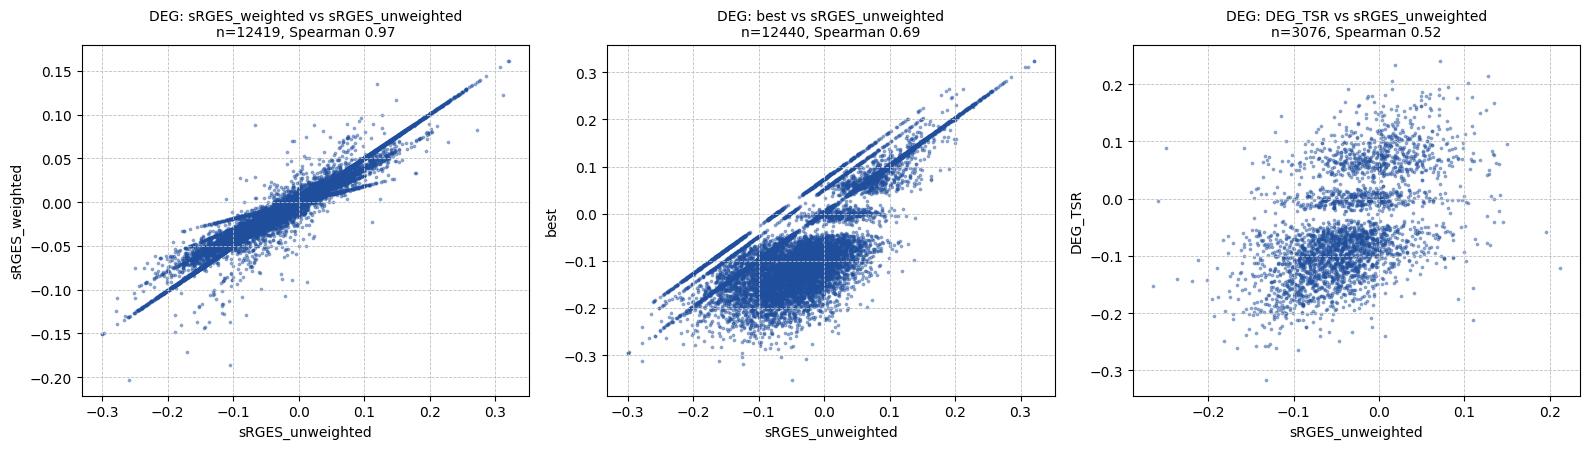

In [7]:
rows = []
for c in CONFIGS:
    piv = s[s.config == c].groupby(['k', 'collapse'])['score'].mean().unstack()
    piv[f'{c}_TSR'] = tsr[c].reindex(piv.index)
    cols = COLLAPSES + [f'{c}_TSR']
    for a_ in range(len(cols)):
        for b_ in range(a_ + 1, len(cols)):
            d = piv[[cols[a_], cols[b_]]].dropna()
            rows.append({'config': c, 'x': cols[a_], 'y': cols[b_], 'n': len(d),
                         'spearman': stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1]).statistic})
agree = pd.DataFrame(rows); display(agree.round(3))

c = CONFIGS[0]
piv = s[s.config == c].groupby(['k', 'collapse'])['score'].mean().unstack(); piv[f'{c}_TSR'] = tsr[c].reindex(piv.index)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (x, y) in zip(ax, [('sRGES_unweighted', 'sRGES_weighted'), ('sRGES_unweighted', 'best'), ('sRGES_unweighted', f'{c}_TSR')]):
    d = piv[[x, y]].dropna()
    a.scatter(d[x], d[y], s=3, alpha=.4, color=BLUE)
    a.set_xlabel(x); a.set_ylabel(y)
    a.set_title(f'{c}: {y} vs {x}\nn={len(d)}, Spearman {stats.spearmanr(d[x], d[y]).statistic:.2f}', fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_agreement.png'), dpi=120); plt.show()

### 4.1 Consensus of the sRGES and wsRGES rankings

For every per-instance configuration (`DEG`, `mith`, `mith_LM`, `mith_pw`) × (`sRGES`, `wsRGES`), the
compounds scored by all eight rankings are re-ranked within each ranking (percentile, low = stronger
reversal) and the eight percentiles are averaged (`mean_pct`). A low `mean_pct` means a compound reverses
the signature in every configuration. `sRGES` and `wsRGES` of the same configuration correlate at about
0.97, so each configuration enters twice with nearly the same information.

In [8]:
C10 = [f'{c}_{v}' for c in ['DEG', 'mith', 'mith_LM', 'mith_pw'] for v in ('sRGES', 'wsRGES') if f'{c}_{v}' in W]
P10 = consensus(W, C10)
print(f'{len(C10)} rankings; {len(P10)} compounds scored by all of them (percentiles recomputed on these)')
t = P10.head(25).round(1); t.insert(0, 'drug', t.index.map(NAME)); display(t)
print('known drugs in this consensus:')
display(P10.reindex(KNOWN)[['mean_pct', 'consensus_rank']].round(1).assign(of=len(P10)))

8 rankings; 12419 compounds scored by all of them (percentiles recomputed on these)


,drug,DEG_sRGES,DEG_wsRGES,mith_sRGES,mith_wsRGES,mith_LM_sRGES,mith_LM_wsRGES,mith_pw_sRGES,mith_pw_wsRGES,mean_pct,consensus_rank
k,,,,,,,,,,,
brdk83860226,BRD-K83860226,1.0,1.0,0.4,0.7,0.0,0.1,0.1,0.5,0.5,1
brdk43862194,BRD-K43862194,0.2,0.3,0.5,0.9,1.0,1.2,1.9,2.1,1.0,2
brdk74566474,BRD-K74566474,0.1,0.1,0.2,0.6,0.0,0.2,3.7,3.5,1.1,3
brdk20091307,BRD-K20091307,4.1,3.4,0.3,0.7,0.2,0.5,0.0,0.3,1.2,4
brdk75199888,BRD-K75199888,1.0,1.0,1.5,1.8,0.5,0.7,1.4,1.7,1.2,5
brdk09110452,BRD-K09110452,2.1,1.9,0.1,0.3,0.9,1.1,1.8,2.1,1.3,6
cyanopindolol,cyanopindolol,4.9,0.2,2.6,0.0,2.4,0.1,0.3,0.0,1.3,7
brdk84293326,BRD-K84293326,5.1,4.1,0.1,0.4,0.8,1.1,0.4,0.7,1.6,8
sr147778,SR-147778,6.3,0.4,1.6,0.0,2.4,0.1,2.2,0.1,1.6,9


known drugs in this consensus:


,mean_pct,consensus_rank,of
k,,,
riluzole,29.8,2329,12419
edaravone,32.3,2724,12419
dextromethorphan,71.5,10282,12419
quinidine,67.6,9639,12419
phenylbutyrate,70.3,10091,12419


## 5. Top-ranked compounds

In [9]:
TOP = 20
for c in CONFIGS:
    tabs = {}
    for coll in COLLAPSES:
        d = s[(s.config == c) & (s.collapse == coll)].sort_values('score').head(TOP)
        tabs[coll] = [f'{n} ({v:+.3f}, {int(k)} inst)' for n, v, k in zip(d.pert_iname, d.score, d.n_instances)]
    t = tsr[c].sort_values().head(TOP)
    tabs[f'{c}_TSR (pooled 6h_24h)'] = [f'{n} ({v:+.3f})' for n, v in t.items()]
    print(f'=== {c} ==='); display(pd.DataFrame(tabs, index=range(1, TOP + 1)))

MIN_INST = 3
for c in CONFIGS:
    tabs = {}
    for coll in COLLAPSES:
        d = s[(s.config == c) & (s.collapse == coll) & (s.n_instances >= MIN_INST)].sort_values('score').head(TOP)
        tabs[coll] = [f'{n} ({v:+.3f}, {int(k)} inst, {int(l)} lines)' for n, v, k, l in zip(d.pert_iname, d.score, d.n_instances, d.n_cell_lines)]
    print(f'=== {c}, compounds with >= {MIN_INST} instances ==='); display(pd.DataFrame(tabs, index=range(1, TOP + 1)))
u = s[(s.config == CONFIGS[0]) & (s.collapse == 'sRGES_unweighted')]
for k, g in u.groupby(pd.cut(u.n_instances, [0, 1, 2, 5, 20, 10**6], labels=['1', '2', '3-5', '6-20', '>20']), observed=False):
    print(f'instances {k:>5s}: n={len(g):5d}  score sd {g.score.std():.3f}  share in top 1% {100 * (g.score <= u.score.quantile(.01)).mean():.1f}%')

=== DEG ===


,sRGES_weighted,sRGES_unweighted,best,DEG_TSR (pooled 6h_24h)
1,"butyrolactone (-0.203, 1 inst)","BRD-K90827020 (-0.300, 1 inst)","daunorubicin (-0.352, 107 inst)",nvpbgj398 (-0.316)
2,"BG-1014 (-0.186, 1 inst)","BRD-K42182933 (-0.300, 1 inst)","withaferin-a (-0.318, 148 inst)",brdk27630941 (-0.265)
3,"BRD-K12482929 (-0.171, 1 inst)","BRD-K11930946 (-0.297, 1 inst)","auranofin (-0.313, 50 inst)",brdk00203625 (-0.261)
4,"BRD-K90827020 (-0.151, 1 inst)","BRD-K38841486 (-0.278, 3 inst)","BRD-K38841486 (-0.312, 3 inst)",zprolylprolinal (-0.261)
5,"BRD-K42182933 (-0.151, 1 inst)","TP7 (-0.278, 2 inst)","BRD-A93942655 (-0.308, 13 inst)",brdk12540328 (-0.258)
6,"BRD-K11930946 (-0.150, 1 inst)","BRD-K99171789 (-0.277, 1 inst)","SD-6-035-B3 (-0.304, 7 inst)",amuvatinib (-0.258)
7,"BML-278 (-0.148, 1 inst)","BRD-K15224350 (-0.267, 1 inst)","dopamine (-0.304, 13 inst)",yc1 (-0.258)
8,"BRD-K61260019 (-0.144, 1 inst)","ambelline (-0.265, 1 inst)","BRD-K90827020 (-0.296, 1 inst)",y27632 (-0.254)
9,"BRD-K56994829 (-0.143, 1 inst)","BRD-K92014291 (-0.261, 1 inst)","CD-1530 (-0.296, 44 inst)",brl54443 (-0.249)
10,"BG-1023 (-0.141, 1 inst)","BRD-K91339294 (-0.260, 1 inst)","BRD-K42182933 (-0.296, 1 inst)",erythrosine (-0.248)


=== mith ===


,sRGES_weighted,sRGES_unweighted,best,mith_TSR (pooled 6h_24h)
1,"BRD-A14795281 (-0.132, 1 inst)","BRD-K14628187 (-0.203, 1 inst)","wortmannin (-0.175, 582 inst)",nvpbgj398 (-0.218)
2,"RN1 (-0.125, 1 inst)","BRD-K02861439 (-0.192, 1 inst)","idarubicin (-0.170, 86 inst)",erythrosine (-0.214)
3,"BRD-K13528168 (-0.118, 1 inst)","BRD-K49906853 (-0.191, 1 inst)","quizartinib (-0.170, 33 inst)",yc1 (-0.207)
4,"SR-147778 (-0.117, 1 inst)","BRD-K49595590 (-0.189, 1 inst)","etoposide (-0.170, 35 inst)",torin1 (-0.205)
5,"BRD-K61260019 (-0.113, 1 inst)","BRD-K18327813 (-0.187, 1 inst)","BRD-K85275009 (-0.167, 11 inst)",brdk12540328 (-0.205)
6,"cyanopindolol (-0.111, 1 inst)","BRD-K89257372 (-0.186, 1 inst)","carmofur (-0.167, 4 inst)",saquinavir (-0.204)
7,"Z-36 (-0.111, 1 inst)","BRD-K76665419 (-0.184, 1 inst)","L-690330 (-0.166, 26 inst)",mephentermine (-0.204)
8,"BRD-K07653295 (-0.111, 1 inst)","BRD-K09110452 (-0.183, 1 inst)","SA-1458306 (-0.165, 10 inst)",brdk70229243 (-0.200)
9,"aminoresveratrol (-0.109, 2 inst)","BRD-K46319090 (-0.183, 1 inst)","BRD-K73610817 (-0.165, 12 inst)",asn05257430 (-0.200)
10,"ionomycin (-0.109, 2 inst)","BRD-K82015643 (-0.183, 1 inst)","resveratrol (-0.163, 41 inst)",zprolylprolinal (-0.200)


=== mith_LM ===


,sRGES_weighted,sRGES_unweighted,best,mith_LM_TSR (pooled 6h_24h)
1,"BRD-K56994829 (-0.165, 1 inst)","BRD-K87888439 (-0.255, 1 inst)","daunorubicin (-0.283, 107 inst)",nvpbgj398 (-0.248)
2,"BRD-K61260019 (-0.161, 1 inst)","BRD-K83860226 (-0.253, 1 inst)","CHEMBL-399379 (-0.276, 50 inst)",erythrosine (-0.227)
3,"diaminoquinazoline (-0.152, 1 inst)","BRD-K74566474 (-0.242, 1 inst)","GSK-1904529A (-0.264, 28 inst)",nvpbez235 (-0.225)
4,"butyrolactone (-0.145, 1 inst)","BRD-K38841486 (-0.242, 3 inst)","CD-1530 (-0.257, 44 inst)",myriocin (-0.224)
5,"BRD-A11009626 (-0.144, 2 inst)","BRD-K45850369 (-0.239, 1 inst)","BRD-K55149044 (-0.254, 13 inst)",baccatiniii (-0.220)
6,"BRD-K13528168 (-0.141, 1 inst)","BRD-K92014291 (-0.237, 1 inst)","AKT-inhibitor-1-2 (-0.253, 48 inst)",brdk12540328 (-0.216)
7,"desmethylclomipramine (-0.140, 2 inst)","W-12 (-0.237, 1 inst)","XMD-132 (-0.251, 30 inst)",arcyriaflavina (-0.215)
8,"aminoresveratrol (-0.138, 2 inst)","BRD-K19742528 (-0.235, 1 inst)","KUC103898N (-0.248, 6 inst)",cyt387 (-0.212)
9,"BRD-K12482929 (-0.130, 1 inst)","linoleic-acid (-0.231, 2 inst)","BRD-K93291593 (-0.245, 4 inst)",brdk46285453 (-0.212)
10,"BRD-K10609180 (-0.129, 1 inst)","BRD-K12182524 (-0.229, 2 inst)","BRD-K38841486 (-0.244, 3 inst)",wortmannin (-0.207)


... (7 outputs left out)

,sRGES_weighted,sRGES_unweighted,best
1,"plumbagin (-0.124, 4 inst, 2 lines)","BRD-K38841486 (-0.242, 3 inst, 2 lines)","daunorubicin (-0.283, 107 inst, 17 lines)"
2,"JS-K (-0.114, 3 inst, 2 lines)","BRD-K31931684 (-0.223, 3 inst, 2 lines)","CHEMBL-399379 (-0.276, 50 inst, 40 lines)"
3,"BRD-A78236793 (-0.114, 3 inst, 2 lines)","Y-27152 (-0.190, 3 inst, 3 lines)","GSK-1904529A (-0.264, 28 inst, 13 lines)"
4,"BRD-K38841486 (-0.107, 3 inst, 2 lines)","SA-247508 (-0.188, 4 inst, 1 lines)","CD-1530 (-0.257, 44 inst, 32 lines)"
5,"bafilomycin (-0.097, 4 inst, 2 lines)","BRD-K36620425 (-0.183, 3 inst, 1 lines)","BRD-K55149044 (-0.254, 13 inst, 8 lines)"
6,"BRD-K31931684 (-0.095, 3 inst, 2 lines)","SA-1938820 (-0.183, 4 inst, 1 lines)","AKT-inhibitor-1-2 (-0.253, 48 inst, 29 lines)"
7,"BRD-K36620425 (-0.092, 3 inst, 1 lines)","BRD-K94412749 (-0.178, 3 inst, 2 lines)","XMD-132 (-0.251, 30 inst, 15 lines)"
8,"KDM-103 (-0.090, 3 inst, 2 lines)","BRD-K36591038 (-0.176, 3 inst, 3 lines)","KUC103898N (-0.248, 6 inst, 4 lines)"
9,"BRD-K36591038 (-0.090, 3 inst, 3 lines)","erythrosine (-0.176, 16 inst, 9 lines)","BRD-K93291593 (-0.245, 4 inst, 2 lines)"
10,"IQ1 (-0.088, 4 inst, 2 lines)","BRD-K65242613 (-0.174, 10 inst, 7 lines)","BRD-K38841486 (-0.244, 3 inst, 2 lines)"


=== mith_pw, compounds with >= 3 instances ===


,sRGES_weighted,sRGES_unweighted,best
1,"BRD-K23986500 (-0.425, 3 inst, 2 lines)","SA-1459854 (-0.576, 4 inst, 2 lines)","BRD-K83213280 (-0.650, 10 inst, 6 lines)"
2,"BRD-A42610307 (-0.407, 3 inst, 2 lines)","chlorphenamine (-0.568, 4 inst, 4 lines)","brucine (-0.650, 8 inst, 7 lines)"
3,"rimonabant (-0.379, 3 inst, 2 lines)","SA-1459002 (-0.567, 3 inst, 2 lines)","etanidazole (-0.643, 8 inst, 4 lines)"
4,"BRD-A86146706 (-0.376, 4 inst, 2 lines)","SA-1459172 (-0.566, 3 inst, 2 lines)","austricine (-0.639, 7 inst, 5 lines)"
5,"BG-1004 (-0.366, 4 inst, 2 lines)","BRD-K05885800 (-0.543, 3 inst, 2 lines)","scriptaid (-0.639, 44 inst, 14 lines)"
6,"BRD-K47535255 (-0.352, 3 inst, 2 lines)","peruvoside (-0.542, 3 inst, 1 lines)","phenanthridone (-0.633, 13 inst, 6 lines)"
7,"BRD-K33445737 (-0.344, 3 inst, 2 lines)","SA-1459234 (-0.530, 6 inst, 3 lines)","BRD-A41649729 (-0.633, 11 inst, 3 lines)"
8,"BG-1028 (-0.336, 4 inst, 2 lines)","SA-1462738 (-0.523, 4 inst, 1 lines)","azathioprine (-0.632, 8 inst, 6 lines)"
9,"BRD-K43631199 (-0.336, 3 inst, 2 lines)","BRD-K96072301 (-0.522, 3 inst, 1 lines)","BRD-K64877338 (-0.631, 7 inst, 3 lines)"
10,"BG-1029 (-0.327, 4 inst, 2 lines)","BRD-K70595525 (-0.521, 3 inst, 1 lines)","chlorphenamine (-0.630, 4 inst, 4 lines)"


instances     1: n= 5041  score sd 0.110  share in top 1% 2.1%
instances     2: n= 2090  score sd 0.086  share in top 1% 0.7%
instances   3-5: n= 2472  score sd 0.066  share in top 1% 0.2%
instances  6-20: n= 2307  score sd 0.051  share in top 1% 0.0%
instances   >20: n=  532  score sd 0.043  share in top 1% 0.0%


## 6. Effect of the cell-line weight

Weighted sRGES multiplies every instance by `cor / max(cor)` (cor = median correlation of the line
with the ALS CNS samples; 64 lines: 58 from CCLE, 4 from HPA, NPC and NEU from GEO GSE144279) and leaves
out the 7 lines without a weight (ASC, CD34, FIBRNPC, HS27A, NKDBA, PHH, SKB). In ALS the largest weight is
NEU (0.605), so `max(cor)` = 0.605.

In [10]:
for c in CONFIGS:
    w = s[(s.config == c) & (s.collapse == 'sRGES_weighted')].set_index('pert_iname')['score']
    u = s[(s.config == c) & (s.collapse == 'sRGES_unweighted')].set_index('pert_iname')['score']
    d = pd.concat([u.rename('unweighted'), w.rename('weighted')], axis=1).dropna()
    ru, rw = d['unweighted'].rank(pct=True), d['weighted'].rank(pct=True)
    print(f'{c}: n={len(d)}, Spearman {stats.spearmanr(d.unweighted, d.weighted).statistic:.3f}; '
          f'median |percentile shift| {100 * (ru - rw).abs().median():.1f} points; '
          f'top-100 overlap {len(set(d.unweighted.nsmallest(100).index) & set(d.weighted.nsmallest(100).index))}/100')
display(weights.sort_values('cor', ascending=False).head(10).round(3))

DEG: n=12421, Spearman 0.969; median |percentile shift| 2.8 points; top-100 overlap 77/100


mith: n=12421, Spearman 0.965; median |percentile shift| 3.2 points; top-100 overlap 51/100
mith_LM: n=12421, Spearman 0.969; median |percentile shift| 3.1 points; top-100 overlap 53/100


mith_pw: n=12421, Spearman 0.968; median |percentile shift| 3.1 points; top-100 overlap 44/100


,lincs_cell_id,cor,source
63,NEU,0.605,"GEO GSE144279 8330-8 neurons, same donor iPSC,..."
62,NPC,0.474,"GEO GSE144279 8330-8 NPC, same donor iPSC, ext..."
28,NCIH1694,0.424,DepMap
42,SKMEL1,0.347,DepMap
22,JHUEM2,0.345,DepMap
2,A673,0.334,DepMap
29,NCIH1836,0.331,DepMap
43,SKMEL28,0.325,DepMap
60,HEK293T,0.317,"HPA HEK293, parent line"
56,VCAP,0.305,DepMap


## 7. Known ALS (als_NYGC) drugs

From `als_NYGC_known_drug_ranks.tsv` (the pipeline's `known_drugs` validation). Percentile = rank(pct) × 100 in
ascending score (low = stronger reversal): `percentile` among all the compounds the ranking scores (own universe),
`percentile_shared_DEG` among the TSR ∩ per-instance compounds (section 2.1), `percentile_stratum` among the
compounds with a similar number of instances (stratum). NaN = not scored.

In [11]:
R = [f'{c}_TSR' for c in TSR_CONFIGS] + [f'{c}_{v}' for c in CONFIGS for v in ('sRGES', 'wsRGES', 'best')]
for v in ['percentile', 'percentile_shared_DEG', 'percentile_stratum', 'score']:
    print(v)
    display(kn[kn.ranking.isin(R)].pivot_table(index='drug_key', columns='ranking', values=v).reindex(index=KNOWN, columns=R).round(3))
print('instances behind each known drug (per-instance route):')
display(kn[kn.ranking.isin([f'{c}_sRGES' for c in CONFIGS])].pivot_table(index='drug_key', columns='ranking',
        values=['n_instances', 'n_cell_lines']).reindex(KNOWN))

percentile


ranking,DEG_TSR,DEG_LM_TSR,mith_TSR,mith_LM_TSR,mith_pw_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,mith_sRGES,mith_wsRGES,mith_best,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best
drug_key,,,,,,,,,,,,,,,,,
riluzole,11.052,15.182,13.722,11.441,12.760,64.301,68.991,4.719,26.576,4.630,3.344,29.735,11.724,12.074,27.371,5.202,3.939
edaravone,NaN,NaN,NaN,NaN,NaN,15.418,20.050,31.841,36.672,35.687,5.547,23.071,25.574,14.859,51.632,50.495,49.887
dextromethorphan,75.287,57.684,72.214,59.795,40.515,66.286,74.869,53.987,72.170,80.820,30.860,71.921,78.332,45.181,63.191,64.256,36.274
quinidine,71.437,68.736,60.913,43.729,45.638,62.749,62.050,30.446,71.640,76.214,31.905,64.518,64.804,18.987,69.180,69.700,22.657
phenylbutyrate,88.327,93.853,85.532,94.272,96.989,53.167,25.815,36.415,80.072,94.541,24.582,71.238,75.409,23.999,68.071,94.323,25.547


percentile_shared_DEG


ranking,DEG_TSR,DEG_LM_TSR,mith_TSR,mith_LM_TSR,mith_pw_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,mith_sRGES,mith_wsRGES,mith_best,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best
drug_key,,,,,,,,,,,,,,,,,
riluzole,10.956,15.150,13.882,11.590,12.809,74.285,79.258,9.493,12.646,0.391,7.282,22.529,3.940,25.910,10.371,0.488,10.078
edaravone,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dextromethorphan,75.325,57.640,72.302,59.948,40.377,76.691,86.324,81.762,82.965,88.766,54.194,84.655,89.938,73.114,69.636,71.215,63.573
quinidine,71.619,68.856,60.988,43.742,45.481,72.529,71.084,54.519,82.185,85.314,55.787,75.000,74.927,39.629,79.616,79.290,44.896
phenylbutyrate,88.166,93.726,85.306,94.197,96.912,56.730,16.900,62.321,90.117,97.297,45.351,83.648,87.007,47.773,77.763,97.558,49.220


percentile_stratum


ranking,DEG_TSR,DEG_LM_TSR,mith_TSR,mith_LM_TSR,mith_pw_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,mith_sRGES,mith_wsRGES,mith_best,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best
drug_key,,,,,,,,,,,,,,,,,
riluzole,NaN,NaN,NaN,NaN,NaN,81.818,81.707,11.462,15.613,0.076,8.498,25.000,2.058,35.672,6.719,0.076,11.858
edaravone,NaN,NaN,NaN,NaN,NaN,16.324,21.820,21.063,32.934,35.005,2.729,25.132,28.180,7.851,52.609,52.368,43.322
dextromethorphan,NaN,NaN,NaN,NaN,NaN,85.277,88.720,94.862,94.368,94.131,74.012,93.379,92.988,91.304,80.435,73.704,80.731
quinidine,NaN,NaN,NaN,NaN,NaN,80.138,79.553,74.012,93.281,96.983,76.087,84.783,87.263,55.138,89.328,92.067,59.585
phenylbutyrate,NaN,NaN,NaN,NaN,NaN,51.194,20.204,45.488,87.778,97.917,27.641,77.337,82.272,26.325,72.238,97.602,28.713


score


ranking,DEG_TSR,DEG_LM_TSR,mith_TSR,mith_LM_TSR,mith_pw_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,mith_sRGES,mith_wsRGES,mith_best,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best
drug_key,,,,,,,,,,,,,,,,,
riluzole,-0.149,-0.116,-0.136,-0.142,-0.386,-0.003,0.004,-0.197,-0.085,-0.065,-0.138,-0.075,-0.053,-0.148,-0.296,-0.244,-0.538
edaravone,NaN,NaN,NaN,NaN,NaN,-0.115,-0.043,-0.120,-0.066,-0.027,-0.133,-0.088,-0.035,-0.142,-0.086,-0.042,-0.317
dextromethorphan,0.010,-0.042,-0.060,-0.074,-0.270,0.001,0.011,-0.081,0.026,0.021,-0.104,0.025,0.020,-0.093,0.015,0.012,-0.378
quinidine,0.001,0.004,-0.077,-0.093,-0.256,-0.006,-0.003,-0.123,0.025,0.016,-0.103,0.004,0.002,-0.134,0.075,0.035,-0.433
phenylbutyrate,0.072,0.101,0.060,0.080,0.363,-0.029,-0.037,-0.112,0.047,0.038,-0.110,0.023,0.016,-0.125,0.064,0.146,-0.421


instances behind each known drug (per-instance route):


n_cell_lines                                        n_instances                                       
ranking             DEG_sRGES mith_LM_sRGES mith_pw_sRGES mith_sRGES   DEG_sRGES mith_LM_sRGES mith_pw_sRGES mith_sRGES
drug_key                                                                                                               
riluzole                  7.0           7.0           7.0        7.0        10.0          10.0          10.0       10.0
edaravone                 2.0           2.0           2.0        2.0         2.0           2.0           2.0        2.0
dextromethorphan          9.0           9.0           9.0        9.0        10.0          10.0          10.0       10.0
quinidine                10.0          10.0          10.0       10.0        15.0          15.0          15.0       15.0
phenylbutyrate            5.0           5.0           5.0        5.0         5.0           5.0           5.0        5.0

## 8. Configurations with CS runs on every cell line

The sRGES tables cover the configurations whose per-instance CS runs exist for all 71 cell lines
(`als_NYGC_srges_cs_runs_used.tsv`); any other configuration is listed below.

In [12]:
print('configurations without CS runs on all lines:', PENDING or 'none')

configurations without CS runs on all lines: none


## 9. Notes

The numbers and the reading of these tables are in the case-study report
(`other_outputs/case_studies/als_NYGC/report_srges_als_NYGC.md`); this notebook shows the tables and figures behind it.
Every number above is printed by the cell that computes it.

## 10. Top-line sRGES: only the cell lines above a random-pair cutoff

sRGES averages over every LINCS line and wsRGES over every line with a weight, although most lines sit in the middle of the
similarity distribution. The top-line variants keep only the LINCS lines whose weight (median
Spearman correlation with the case samples, primary gene set `binchen2017_iqr5000`) exceeds a
cutoff taken from the correlation between two unrelated cell lines: all 40,000 pairs between two
disjoint sets of 200 random CCLE lines (seed 0). Cutoffs: `q3` = third quartile, `median`.
Collapses `sRGES_(un)weighted_top_<cutoff>` (`<config>_sRGES_topQ3` / `_wsRGES_topQ3` /
`_sRGES_topMed` / `_wsRGES_topMed` in the rankings); dose/time offsets as in sRGES; a compound is
scored only if it was profiled on at least one top line. `DEG_LM` = `DEG` in this route (landmark-only
drug signatures).

,comparison,n_pairs,q1,median,q3
0,random CCLE pairs (200 x 200),40000,0.385,0.451,0.554
1,LINCS line pairs,1653,0.446,0.514,0.600


cutoff q3 = 0.554: 1 lines NEU (0.605)
cutoff median = 0.451: 2 lines NEU (0.605), NPC (0.474)


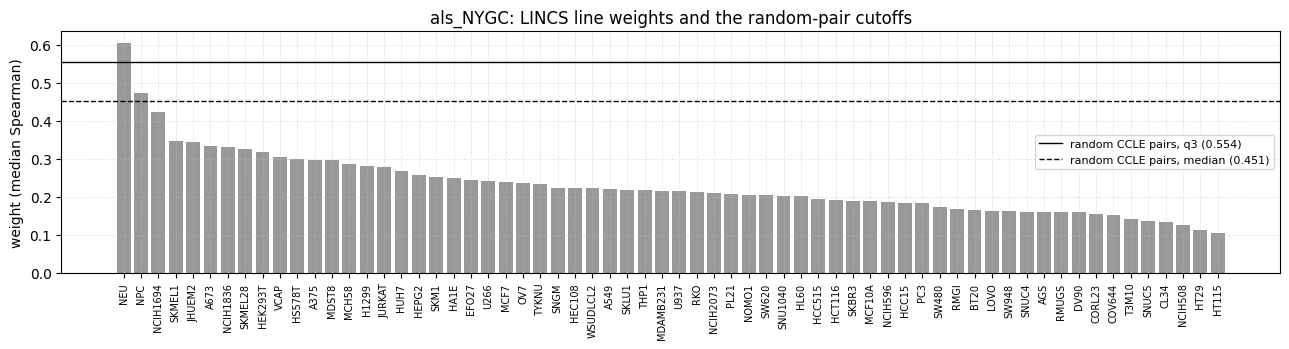

In [13]:
OO = os.path.join(NETCOS_ROOT, 'other_outputs', 'case_studies', DISEASE)
ref = pd.read_csv(os.path.join(OO, f'{DISEASE}_ccle_reference_scale.tsv'), sep='\t')
top = pd.read_csv(os.path.join(OO, f'{DISEASE}_top_cell_lines.tsv'), sep='\t')
wts = pd.read_csv(os.path.join(OO, f'{DISEASE}_cell_line_weights.tsv'), sep='\t').sort_values('cor', ascending=False)
display(ref.round(3))
for cut, g in top.groupby('cutoff', sort=False):
    l = g.dropna(subset=['lincs_cell_id'])
    print(f'cutoff {cut} = {g.threshold.iloc[0]:.3f}: {len(l)} lines', ', '.join(f'{c} ({v:.3f})' for c, v in zip(l.lincs_cell_id, l.cor)))
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(range(len(wts)), wts.cor, color='0.6')
for q, ls_ in (('q3', '-'), ('median', '--')):
    ax.axhline(ref[q].iloc[0], color='k', ls=ls_, lw=1, label=f'random CCLE pairs, {q} ({ref[q].iloc[0]:.3f})')
ax.set_xticks(range(len(wts))); ax.set_xticklabels(wts.lincs_cell_id, rotation=90, fontsize=7)
ax.set_ylabel('weight (median Spearman)'); ax.set_title(f'{DISEASE}: LINCS line weights and the random-pair cutoffs')
ax.grid(ls='--', alpha=.4); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 10.1 Agreement with the all-line collapses and the TSR route

Spearman correlation and top-50 overlap on the compounds scored by both (low score = stronger reversal).

In [14]:
TSR = lambda cfg: tsr[cfg]   # pooled 6h_24h TSR scores of section 1
sp = pd.read_csv(os.path.join(OO, f'{DISEASE}_srges_per_drug.tsv'), sep='\t')
sp['k'] = sp['pert_iname'].astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
TOPC = [c for c in sp.collapse.unique() if '_top_' in c]
REFC = ['sRGES_unweighted', 'sRGES_weighted', 'best']
def overlap(a, b, n=50):
    return len(set(a.nsmallest(n).index) & set(b.nsmallest(n).index))

if not TOPC:
    print('no top-line rankings for this study (no LINCS line above either cutoff)')
else:
    rows = []
    for cfg, d in sp.groupby('config', sort=False):
        piv = d.groupby(['k', 'collapse'])['score'].mean().unstack()
        piv[f'{cfg}_TSR'] = TSR(cfg).reindex(piv.index)
        for t in TOPC:
            for r in REFC + [f'{cfg}_TSR']:
                x = piv[[t, r]].dropna()
                rows.append({'config': cfg, 'top_collapse': t, 'vs': r, 'n_drugs_top': int(piv[t].notna().sum()), 'n_shared': len(x),
                             'spearman': stats.spearmanr(x[t], x[r]).statistic if len(x) > 2 else np.nan,
                             'top50_overlap': overlap(x[t], x[r]) if len(x) >= 50 else np.nan})
    CMP = pd.DataFrame(rows)
    print('Spearman on shared compounds:')
    display(CMP.pivot_table(index=['config', 'top_collapse'], columns='vs', values='spearman').round(3))
    print('top-50 overlap on shared compounds (both re-ranked on the shared set):')
    display(CMP.pivot_table(index=['config', 'top_collapse'], columns='vs', values='top50_overlap'))
    print('compounds scored / shared with the TSR route:')
    display(CMP[CMP.vs.str.endswith('_TSR')][['config', 'top_collapse', 'n_drugs_top', 'n_shared']])

Spearman on shared compounds:


vs                                   DEG_TSR   best  mith_LM_TSR  mith_TSR  mith_pw_TSR  sRGES_unweighted  sRGES_weighted
config  top_collapse                                                                                                     
DEG     sRGES_unweighted_top_median    0.325  0.304          NaN       NaN          NaN             0.485           0.676
        sRGES_unweighted_top_q3        0.226  0.172          NaN       NaN          NaN             0.436           0.626
        sRGES_weighted_top_median      0.323  0.301          NaN       NaN          NaN             0.488           0.684
        sRGES_weighted_top_q3          0.226  0.172          NaN       NaN          NaN             0.436           0.626
mith    sRGES_unweighted_top_median      NaN  0.347          NaN     0.285          NaN             0.567           0.699
        sRGES_unweighted_top_q3          NaN  0.158          NaN     0.154          NaN             0.479           0.640
        sRGES_weighted_top_median        NaN  0.334          NaN     0.272          NaN             0.573           0.714
        sRGES_weighted_top_q3            NaN  0.158          NaN     0.154          NaN             0.479           0.640
mith_LM sRGES_unweighted_top_median      NaN  0.376        0.329       NaN          NaN             0.559           0.710
        sRGES_unweighted_top_q3          NaN  0.244        0.220       NaN          NaN             0.537           0.689
        sRGES_weighted_top_median        NaN  0.366        0.325       NaN          NaN             0.566           0.722
        sRGES_weighted_top_q3            NaN  0.244        0.220       NaN          NaN             0.537           0.689
mith_pw sRGES_unweighted_top_median      NaN  0.307          NaN       NaN        0.283             0.549           0.702
        sRGES_unweighted_top_q3          NaN  0.232          NaN       NaN        0.301             0.552           0.719
        sRGES_weighted_top_median        NaN  0.303          NaN       NaN        0.280             0.555           0.716
        sRGES_weighted_top_q3            NaN  0.232          NaN       NaN        0.301             0.552           0.719

top-50 overlap on shared compounds (both re-ranked on the shared set):


vs                                   DEG_TSR  best  mith_LM_TSR  mith_TSR  mith_pw_TSR  sRGES_unweighted  sRGES_weighted
config  top_collapse                                                                                                    
DEG     sRGES_unweighted_top_median      7.0   6.0          NaN       NaN          NaN               6.0             5.0
        sRGES_unweighted_top_q3         11.0   7.0          NaN       NaN          NaN              17.0            15.0
        sRGES_weighted_top_median        8.0   6.0          NaN       NaN          NaN              10.0             8.0
        sRGES_weighted_top_q3           11.0   7.0          NaN       NaN          NaN              17.0            15.0
mith    sRGES_unweighted_top_median      NaN   7.0          NaN       3.0          NaN              15.0             8.0
        sRGES_unweighted_top_q3          NaN   6.0          NaN      15.0          NaN              16.0            14.0
        sRGES_weighted_top_median        NaN   8.0          NaN       4.0          NaN              14.0            12.0
        sRGES_weighted_top_q3            NaN   6.0          NaN      15.0          NaN              16.0            14.0
mith_LM sRGES_unweighted_top_median      NaN   7.0         10.0       NaN          NaN              10.0             7.0
        sRGES_unweighted_top_q3          NaN   5.0          8.0       NaN          NaN              19.0            13.0
        sRGES_weighted_top_median        NaN   6.0         10.0       NaN          NaN              10.0             8.0
        sRGES_weighted_top_q3            NaN   5.0          8.0       NaN          NaN              19.0            13.0
mith_pw sRGES_unweighted_top_median      NaN   3.0          NaN       NaN          5.0              10.0            10.0
        sRGES_unweighted_top_q3          NaN   5.0          NaN       NaN          8.0              16.0            21.0
        sRGES_weighted_top_median        NaN   2.0          NaN       NaN          3.0              18.0            19.0
        sRGES_weighted_top_q3            NaN   5.0          NaN       NaN          8.0              16.0            21.0

compounds scored / shared with the TSR route:


,config,top_collapse,n_drugs_top,n_shared
3,DEG,sRGES_weighted_top_q3,676,383
7,DEG,sRGES_unweighted_top_q3,676,383
11,DEG,sRGES_weighted_top_median,1642,1055
15,DEG,sRGES_unweighted_top_median,1642,1055
19,mith,sRGES_weighted_top_q3,676,383
23,mith,sRGES_unweighted_top_q3,676,383
27,mith,sRGES_weighted_top_median,1642,1055
31,mith,sRGES_unweighted_top_median,1642,1055
35,mith_LM,sRGES_weighted_top_q3,676,383
39,mith_LM,sRGES_unweighted_top_q3,676,383


### 10.2 Known ALS (als_NYGC) drugs in the top-line rankings

In [15]:
sel = [f'{c}_{v}' for c in CONFIGS for v in ('sRGES', 'wsRGES', 'sRGES_topQ3', 'wsRGES_topQ3', 'sRGES_topMed', 'wsRGES_topMed')]
sel = [r for r in sel if r in set(kn.ranking)]
display(kn[kn.ranking.isin(sel)].pivot_table(index='ranking', columns='drug_key', values=['percentile', 'score', 'n_instances']).reindex(sel).round(3))

n_instances                                                   percentile                                                        score            \
drug_key              dextromethorphan edaravone phenylbutyrate quinidine riluzole dextromethorphan edaravone phenylbutyrate quinidine riluzole dextromethorphan edaravone   
ranking                                                                                                                                                                      
DEG_sRGES                         10.0       2.0            5.0      15.0     10.0           66.286    15.418         53.167    62.749   64.301            0.001    -0.115   
DEG_wsRGES                         8.0       2.0            4.0      12.0      9.0           74.869    20.050         25.815    62.050   68.991            0.011    -0.043   
DEG_sRGES_topQ3                    NaN       NaN            1.0       NaN      2.0              NaN       NaN         10.799       NaN   57.101              NaN       NaN   
DEG_wsRGES_topQ3                   NaN       NaN            1.0       NaN      2.0              NaN       NaN         10.799       NaN   57.101              NaN       NaN   
DEG_sRGES_topMed                   1.0       NaN            2.0       1.0      4.0           78.806       NaN         47.503    96.163   77.406            0.067       NaN   
DEG_wsRGES_topMed                  1.0       NaN            2.0       1.0      4.0           76.736       NaN         43.849    95.189   76.005            0.053       NaN   
mith_sRGES                        10.0       2.0            5.0      15.0     10.0           72.170    36.672         80.072    71.640   26.576            0.026    -0.066   
mith_wsRGES                        8.0       2.0            4.0      12.0      9.0           80.820    35.687         94.541    76.214    4.630            0.021    -0.027   
mith_sRGES_topQ3                   NaN       NaN            1.0       NaN      2.0              NaN       NaN         86.243       NaN    5.769              NaN       NaN   
mith_wsRGES_topQ3                  NaN       NaN            1.0       NaN      2.0              NaN       NaN         86.243       NaN    5.769              NaN       NaN   
mith_sRGES_topMed                  1.0       NaN            2.0       1.0      4.0           76.675       NaN         89.769    95.798    8.831            0.068       NaN   
mith_wsRGES_topMed                 1.0       NaN            2.0       1.0      4.0           74.482       NaN         92.509    93.971    5.116            0.054       NaN   
mith_LM_sRGES                     10.0       2.0            5.0      15.0     10.0           71.921    23.071         71.238    64.518   29.735            0.025    -0.088   
mith_LM_wsRGES                     8.0       2.0            4.0      12.0      9.0           78.332    25.574         75.409    64.804   11.724            0.020    -0.035   
mith_LM_sRGES_topQ3                NaN       NaN            1.0       NaN      2.0              NaN       NaN         57.396       NaN   15.680              NaN       NaN   
mith_LM_wsRGES_topQ3               NaN       NaN            1.0       NaN      2.0              NaN       NaN         57.396       NaN   15.680              NaN       NaN   
mith_LM_sRGES_topMed               1.0       NaN            2.0       1.0      4.0           81.912       NaN         69.062    97.077   49.147            0.083       NaN   
mith_LM_wsRGES_topMed              1.0       NaN            2.0       1.0      4.0           80.024       NaN         68.575    95.615   44.336            0.065       NaN   
mith_pw_sRGES                     10.0       2.0            5.0      15.0     10.0           63.191    51.632         68.071    69.180   27.371            0.015    -0.086   
mith_pw_wsRGES                     8.0       2.0            4.0      12.0      9.0           64.256    50.495         94.323    69.700    5.202            0.012    -0.042   
mith_pw_sRGES_topQ3      

### 10.3 Top compounds of the top-line rankings

In [16]:
if not TOPC:
    print('no top-line rankings for this study')
for cfg in (sp.config.unique() if TOPC else []):
    for t in TOPC:
        print(f'=== {cfg} {t}: top 10')
        display(sp[(sp.config == cfg) & (sp.collapse == t)].nsmallest(10, 'score')[['pert_iname', 'score', 'n_instances', 'n_cell_lines']].round(4))

=== DEG sRGES_weighted_top_q3: top 10


,pert_iname,score,n_instances,n_cell_lines
24863,BRD-K23985857,-0.1890,1,1
24864,BRD-K08982647,-0.1864,1,1
24865,BRD-K65085267,-0.1827,1,1
24866,BRD-A78236793,-0.1786,1,1
24867,calcifediol,-0.1784,1,1
24868,acetyl-farnesyl-cysteine,-0.1745,1,1
24869,BRD-K19653414,-0.1741,1,1
24870,BG-1018,-0.1741,1,1
24871,rolipram,-0.1723,1,1
24872,BRD-K79532217,-0.1720,1,1


=== DEG sRGES_unweighted_top_q3: top 10


,pert_iname,score,n_instances,n_cell_lines
25539,BRD-K23985857,-0.1890,1,1
25540,BRD-K08982647,-0.1864,1,1
25541,BRD-K65085267,-0.1827,1,1
25542,BRD-A78236793,-0.1786,1,1
25543,calcifediol,-0.1784,1,1
25544,acetyl-farnesyl-cysteine,-0.1745,1,1
25545,BRD-K19653414,-0.1741,1,1
25546,BG-1018,-0.1741,1,1
25547,rolipram,-0.1723,1,1
25548,BRD-K79532217,-0.1720,1,1


=== DEG sRGES_weighted_top_median: top 10


,pert_iname,score,n_instances,n_cell_lines
26215,butyrolactone,-0.2028,1,1
26216,BRD-K08982647,-0.1864,1,1
26217,BG-1014,-0.1863,1,1
26218,BRD-A09164687,-0.1850,1,1
26219,BRD-K24014699,-0.1843,1,1
26220,BRD-K06589444,-0.1831,1,1
26221,SB-366791,-0.1800,1,1
26222,erythrosine,-0.1786,1,1
26223,Broad-Sai-370,-0.1761,1,1
26224,acetyl-farnesyl-cysteine,-0.1745,1,1


... (22 outputs left out)

=== mith_pw sRGES_weighted_top_median: top 10


,pert_iname,score,n_instances,n_cell_lines
152044,Z-36,-0.5687,1,1
152045,celecoxib,-0.5553,1,1
152046,BRD-K31975688,-0.5469,1,1
152047,BRD-K16934333,-0.5052,1,1
152048,cyanopindolol,-0.4967,1,1
152049,BRD-K61260019,-0.4935,1,1
152050,BRD-K77888550,-0.4878,1,1
152051,BRD-A14795281,-0.4838,1,1
152052,BRD-K65213718,-0.4737,1,1
152053,BRD-K85236313,-0.4732,1,1


=== mith_pw sRGES_unweighted_top_median: top 10


,pert_iname,score,n_instances,n_cell_lines
153687,BRD-K16934333,-0.6446,1,1
153688,cyanopindolol,-0.6338,1,1
153689,BRD-K77888550,-0.6224,1,1
153690,BRD-K65213718,-0.6044,1,1
153691,BRD-K85236313,-0.6038,1,1
153692,suramin,-0.5937,1,1
153693,BRD-K99718824,-0.5866,1,1
153694,BRD-K79793338,-0.5738,1,1
153695,Z-36,-0.5687,1,1
153696,Val-Val-Val,-0.5622,1,1


### 10.4 All rankings: TSR, per-instance all-line and per-instance top-line

Every ranking of sections 1–10 in one place: the five `_TSR` runs, the per-instance `sRGES`,
`wsRGES` and `best` of each configuration, and the top-line `sRGES` / `wsRGES` where a cutoff has lines
(ALS: NEU for `q3`, NEU and NPC for `median`). Spearman correlation on the compounds scored by both rankings of each pair.

33 rankings; top-line rankings: ['DEG_sRGES_topQ3', 'DEG_wsRGES_topQ3', 'DEG_sRGES_topMed', 'DEG_wsRGES_topMed', 'mith_sRGES_topQ3', 'mith_wsRGES_topQ3', 'mith_sRGES_topMed', 'mith_wsRGES_topMed', 'mith_LM_sRGES_topQ3', 'mith_LM_wsRGES_topQ3', 'mith_LM_sRGES_topMed', 'mith_LM_wsRGES_topMed', 'mith_pw_sRGES_topQ3', 'mith_pw_wsRGES_topQ3', 'mith_pw_sRGES_topMed', 'mith_pw_wsRGES_topMed']


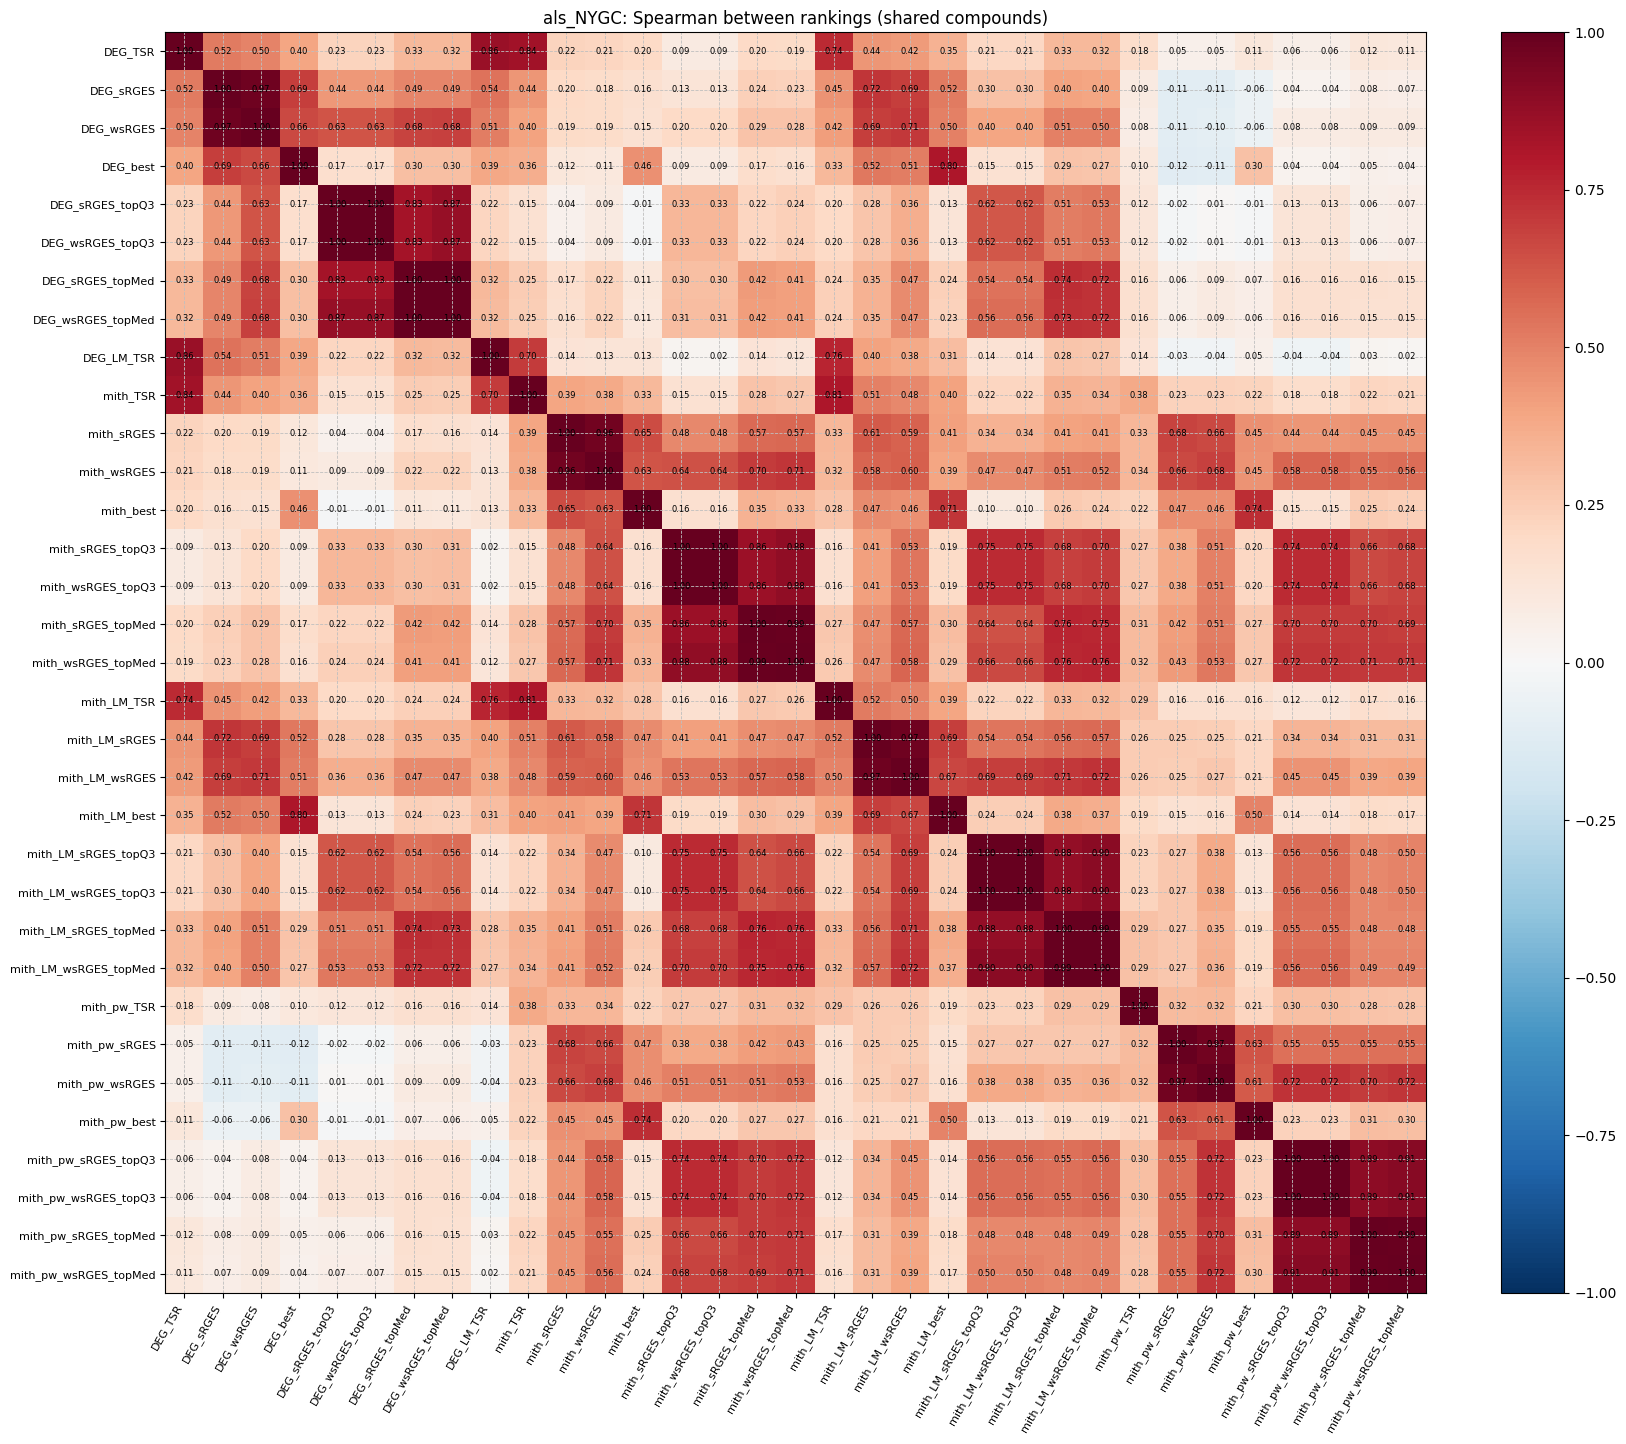

compounds shared by each top-line ranking and the other rankings:


,DEG_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,DEG_sRGES_topQ3,DEG_wsRGES_topQ3,DEG_sRGES_topMed,DEG_wsRGES_topMed,DEG_LM_TSR,mith_TSR,mith_sRGES,mith_wsRGES,mith_best,mith_sRGES_topQ3,mith_wsRGES_topQ3,...,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_LM_sRGES_topQ3,mith_LM_wsRGES_topQ3,mith_LM_sRGES_topMed,mith_LM_wsRGES_topMed,mith_pw_TSR,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best,mith_pw_sRGES_topQ3,mith_pw_wsRGES_topQ3,mith_pw_sRGES_topMed,mith_pw_wsRGES_topMed
DEG_sRGES_topQ3,383,676,676,676,0,676,676,676,383,383,676,676,676,676,676,...,676,676,676,676,676,676,676,383,676,676,676,676,676,676,676
DEG_wsRGES_topQ3,383,676,676,676,676,0,676,676,383,383,676,676,676,676,676,...,676,676,676,676,676,676,676,383,676,676,676,676,676,676,676
DEG_sRGES_topMed,1055,1642,1642,1642,676,676,0,1642,1055,1055,1642,1642,1642,676,676,...,1642,1642,1642,676,676,1642,1642,1055,1642,1642,1642,676,676,1642,1642
DEG_wsRGES_topMed,1055,1642,1642,1642,676,676,1642,0,1055,1055,1642,1642,1642,676,676,...,1642,1642,1642,676,676,1642,1642,1055,1642,1642,1642,676,676,1642,1642
mith_sRGES_topQ3,383,676,676,676,676,676,676,676,383,383,676,676,676,0,676,...,676,676,676,676,676,676,676,383,676,676,676,676,676,676,676
mith_wsRGES_topQ3,383,676,676,676,676,676,676,676,383,383,676,676,676,676,0,...,676,676,676,676,676,676,676,383,676,676,676,676,676,676,676
mith_sRGES_topMed,1055,1642,1642,1642,676,676,1642,1642,1055,1055,1642,1642,1642,676,676,...,1642,1642,1642,676,676,1642,1642,1055,1642,1642,1642,676,676,1642,1642
mith_wsRGES_topMed,1055,1642,1642,1642,676,676,1642,1642,1055,1055,1642,1642,1642,676,676,...,1642,1642,1642,676,676,1642,1642,1055,1642,1642,1642,676,676,1642,1642
mith_LM_sRGES_topQ3,383,676,676,676,676,676,676,676,383,383,676,676,676,676,676,...,676,676,676,0,676,676,676,383,676,676,676,676,676,676,676
mith_LM_wsRGES_topQ3,383,676,676,676,676,676,676,676,383,383,676,676,676,676,676,...,676,676,676,676,0,676,676,383,676,676,676,676,676,676,676


In [17]:
TYPES = ['TSR', 'sRGES', 'wsRGES', 'best', 'sRGES_topQ3', 'wsRGES_topQ3', 'sRGES_topMed', 'wsRGES_topMed']
ALL = [f'{c}_{t}' for c in ['DEG', 'DEG_LM', 'mith', 'mith_LM', 'mith_pw'] for t in TYPES if f'{c}_{t}' in W]
TOPLINE = [r for r in ALL if '_top' in r]
print(f'{len(ALL)} rankings; top-line rankings: {TOPLINE or "none"}')
M = pd.DataFrame(np.eye(len(ALL)), index=ALL, columns=ALL)
NS = pd.DataFrame(0, index=ALL, columns=ALL)
for i, a in enumerate(ALL):
    for b in ALL[i + 1:]:
        d = W[[a, b]].dropna()
        M.loc[a, b] = M.loc[b, a] = stats.spearmanr(d[a], d[b]).statistic if len(d) > 2 else np.nan
        NS.loc[a, b] = NS.loc[b, a] = len(d)
fig, ax = plt.subplots(figsize=(0.42 * len(ALL) + 3, 0.38 * len(ALL) + 2))
im = ax.imshow(M.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(ALL))); ax.set_xticklabels(ALL, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(ALL))); ax.set_yticklabels(ALL, fontsize=8)
for i in range(len(ALL)):
    for j in range(len(ALL)):
        ax.text(j, i, f'{M.values[i, j]:.2f}', ha='center', va='center', fontsize=6)
ax.set_title(f'{DISEASE}: Spearman between rankings (shared compounds)'); plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.show()
if TOPLINE:
    print('compounds shared by each top-line ranking and the other rankings:')
    display(NS.loc[TOPLINE])

### 10.5 Known ALS (als_NYGC) drugs: TSR vs per-instance rankings, all rankings

Filled dots: percentile among all the compounds the ranking scores (its own universe). Open dots:
percentile among the TSR ∩ per-instance compounds (section 2.1; 3,071 of them for `wsRGES`, and in a top-line
ranking only the shared compounds that ranking scores — counts printed below the plot). Percentile 50 = middle
of the ranking.

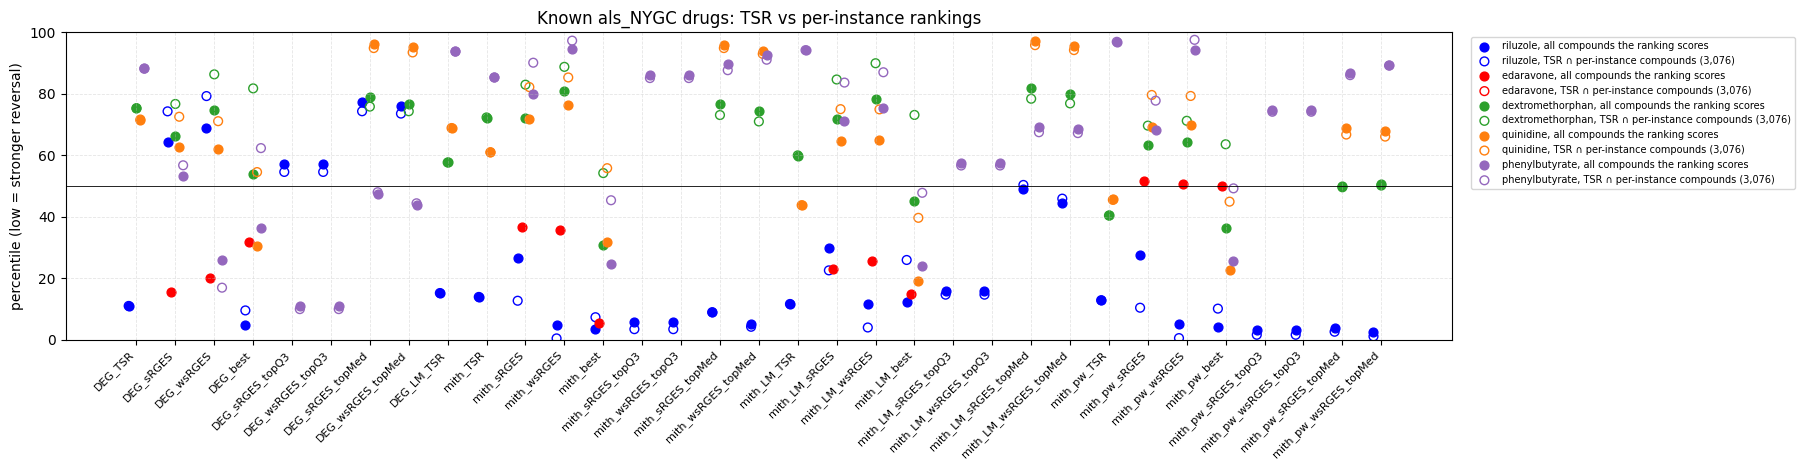

compounds in each ranking: own universe / shared set


,DEG_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,DEG_sRGES_topQ3,DEG_wsRGES_topQ3,DEG_sRGES_topMed,DEG_wsRGES_topMed,DEG_LM_TSR,mith_TSR,mith_sRGES,mith_wsRGES,mith_best,mith_sRGES_topQ3,mith_wsRGES_topQ3,...,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_LM_sRGES_topQ3,mith_LM_wsRGES_topQ3,mith_LM_sRGES_topMed,mith_LM_wsRGES_topMed,mith_pw_TSR,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best,mith_pw_sRGES_topQ3,mith_pw_wsRGES_topQ3,mith_pw_sRGES_topMed,mith_pw_wsRGES_topMed
own,3221,12440,12419,12440,676,676,1642,1642,3221,3221,12440,12419,12440,676,676,...,12440,12419,12440,676,676,1642,1642,3221,12440,12419,12440,676,676,1642,1642
shared,3076,3076,3071,3076,383,383,1055,1055,3076,3076,3076,3071,3076,383,383,...,3076,3071,3076,383,383,1055,1055,3076,3076,3071,3076,383,383,1055,1055


cross-check with the pipeline table (percentile, own universe): max |diff| 1.42e-14


In [18]:
S = set(W['DEG_TSR'].dropna().index) & set(W['DEG_sRGES'].dropna().index)
OWN = W[ALL].apply(pct)
SH = W.loc[W.index.isin(S), ALL].apply(pct)
COLOURS = ['#0000FF', '#FF0000', '#2ca02c', '#ff7f0e', '#9467bd', '#8c564b', '#e377c2']
fig, ax = plt.subplots(figsize=(max(11, 0.55 * len(ALL)), 4.8))
x = np.arange(len(ALL)); step = 0.5 / max(len(KNOWN), 1)
for i, (d, col) in enumerate(zip(KNOWN, COLOURS)):
    dx = (i - (len(KNOWN) - 1) / 2) * step
    ax.scatter(x + dx, OWN.reindex([d]).iloc[0], color=col, s=40, label=f'{d}, all compounds the ranking scores')
    ax.scatter(x + dx, SH.reindex([d]).iloc[0], facecolor='none', edgecolor=col, s=40,
               label=f'{d}, TSR ∩ per-instance compounds ({len(S):,})')
ax.axhline(50, color='k', lw=.6)
ax.set_xticks(x); ax.set_xticklabels(ALL, rotation=45, ha='right', fontsize=8); ax.set_ylim(0, 100)
ax.set_ylabel('percentile (low = stronger reversal)'); ax.grid(ls='--', alpha=.4)
ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title(f'Known {DISEASE} drugs: TSR vs per-instance rankings')
plt.tight_layout(); plt.show()
print('compounds in each ranking: own universe / shared set')
display(pd.DataFrame({'own': W[ALL].notna().sum(), 'shared': W.loc[W.index.isin(S), ALL].notna().sum()}).T)
chk = kn[kn.ranking.isin(ALL)].set_index(['drug_key', 'ranking'])['percentile']
mine = OWN.reindex(KNOWN).stack().rename('pct').reindex(chk.index)
print(f'cross-check with the pipeline table (percentile, own universe): max |diff| {(mine - chk).abs().max():.3g}')

### 10.6 Consensus of all rankings

All the rankings of the matrix above (TSR, per-instance all-line, per-instance top-line where present),
percentiles recomputed on the compounds scored by every one of them and averaged (`mean_pct`); per-family
means for the TSR, all-line and top-line rankings. The common set is limited by the smallest universe
(the top-line universe when there is one, otherwise wsRGES ∩ TSR).

In [19]:
P11 = consensus(W, ALL)
fam = {'mean_TSR': [r for r in ALL if r.endswith('_TSR')],
       'mean_all_line': [r for r in ALL if not r.endswith('_TSR') and '_top' not in r],
       'mean_top_line': TOPLINE}
for k, cols in fam.items():
    if cols:
        P11[k] = P11[cols].mean(axis=1)
print(f'{len(ALL)} rankings; {len(P11)} compounds scored by all of them (percentiles recomputed on these)')
t = P11[['mean_pct', 'consensus_rank'] + [k for k in fam if k in P11]].head(25).round(1)
t.insert(0, 'drug', t.index.map(NAME)); display(t)
print('known drugs in this consensus (NaN = not scored by every ranking):')
display(P11.reindex(KNOWN)[['mean_pct', 'consensus_rank'] + [k for k in fam if k in P11]].round(1).assign(of=len(P11)))

33 rankings; 383 compounds scored by all of them (percentiles recomputed on these)


,drug,mean_pct,consensus_rank,mean_TSR,mean_all_line,mean_top_line
k,,,,,,
su11652,SU-11652,7.5,1,14.4,10.0,3.5
nvpbez235,NVP-BEZ235,8.7,2,10.0,11.1,6.4
staurosporine,staurosporine,11.0,3,32.0,12.7,3.2
wortmannin,wortmannin,13.0,4,10.2,7.2,18.2
aminopurvalanola,aminopurvalanol-a,13.2,5,24.5,10.3,11.8
jw7241,JW-7-24-1,13.6,6,5.7,23.1,9.0
dipropyl5ct,dipropyl-5ct,15.5,7,41.6,12.7,9.4
bisindolylmaleimide,bisindolylmaleimide,16.3,8,11.7,19.0,15.7
ricinine,ricinine,16.4,9,17.7,29.9,5.9


known drugs in this consensus (NaN = not scored by every ranking):


,mean_pct,consensus_rank,mean_TSR,mean_all_line,mean_top_line,of
k,,,,,,
riluzole,22.1,22.0,12.0,22.4,24.9,383
edaravone,NaN,NaN,NaN,NaN,NaN,383
dextromethorphan,NaN,NaN,NaN,NaN,NaN,383
quinidine,NaN,NaN,NaN,NaN,NaN,383
phenylbutyrate,71.3,332.0,93.0,71.5,64.3,383
